총 72개의 파일을 찾아 데이터를 병합합니다...

[완료] 데이터 테이블이 'Resilience_Table_by_Time_Region.csv' 파일로 저장되었습니다!



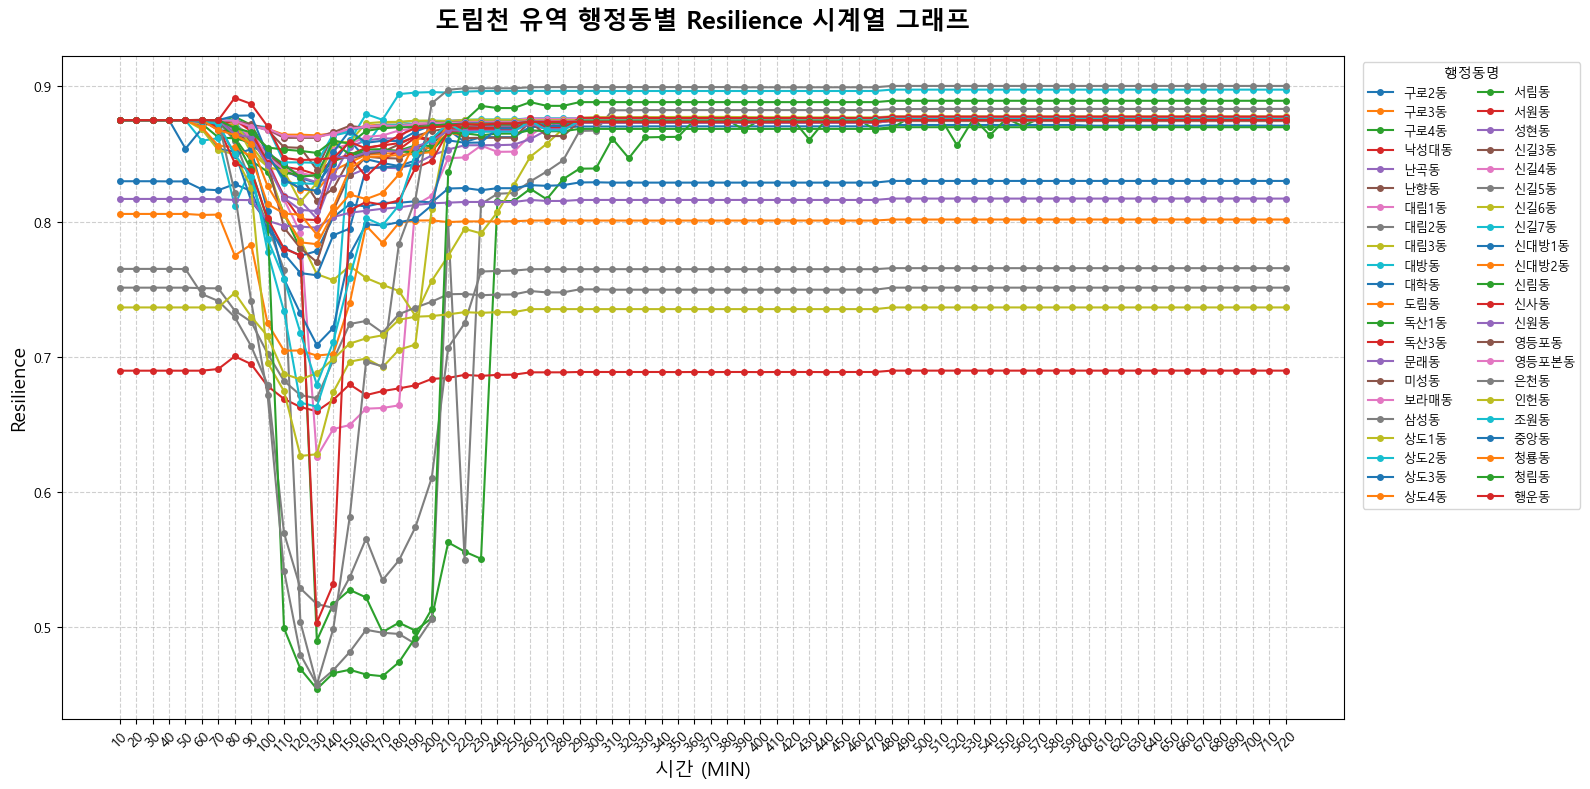

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re
import os

# --- 1. 환경 및 폰트 설정 ---
# 한글 폰트 설정 (Windows는 'Malgun Gothic', Mac은 'AppleGothic' 사용)
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'
    
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

# CSV 파일들을 불러오기 위한 패턴
file_pattern = 'H_*MIN_region_results_final.csv'

# 제외할 행정동 목록 지정
exclude_regions = ['신도림동', '가리봉동', '가산동', '당산1동', '구로5동']

# --- 2. 데이터 수집 및 전처리 ---
file_list = glob.glob(file_pattern)
data = []

if not file_list:
    print(f"'{file_pattern}' 패턴의 파일을 찾을 수 없습니다. 경로를 확인해주세요.")
else:
    print(f"총 {len(file_list)}개의 파일을 찾아 데이터를 병합합니다...")

for file in file_list:
    # [수정 1] 파일명 어디에 있든 숫자+MIN 패턴을 찾아내도록 정규표현식 수정
    match = re.search(r'(\d+)MIN', file)
    
    if match:
        time_min = int(match.group(1))
        
        # [수정 2] 파일 읽기 인코딩 순서 변경 (utf-8 먼저 시도 후 cp949, euc-kr 시도)
        try:
            df = pd.read_csv(file, encoding='utf-8')
        except UnicodeDecodeError:
            try:
                df = pd.read_csv(file, encoding='cp949')
            except UnicodeDecodeError:
                df = pd.read_csv(file, encoding='euc-kr')
        
        # 샘플 데이터 기준 행정동 컬럼명
        region_col = 'ADM_NM_y' 
        
        # 행정동과 Resilience에 결측치가 없는 행만 추출
        df_filtered = df.dropna(subset=[region_col, 'Resilience'])
        
        # 특정 동(신도림동 등 4개) 필터링하여 제외
        df_filtered = df_filtered[~df_filtered[region_col].isin(exclude_regions)]
        
        # 시간, 행정동, Resilience 값만 추출하여 리스트에 추가
        for _, row in df_filtered.iterrows():
            data.append({
                'Time': time_min,
                'Region': row[region_col],
                'Resilience': row['Resilience']
            })

# --- 3. 데이터프레임 피벗팅 ---
df_all = pd.DataFrame(data)

if df_all.empty:
    print("처리할 데이터가 없습니다. 파일 내용이나 컬럼명을 확인해주세요.")
else:
    # 시간(Time)이 행(Index), 행정동(Region)이 열(Column), Resilience가 값이 되도록 피벗 테이블 생성
    df_pivot = df_all.pivot_table(index='Time', columns='Region', values='Resilience')
    df_pivot = df_pivot.sort_index()
    
    # ★ [추가] 리드타임별/행정동별 Resilience 값을 CSV 파일로 저장
    # utf-8-sig 인코딩을 사용하여 엑셀에서 열 때 한글이 깨지지 않도록 설정
    output_filename = "Resilience_Table_by_Time_Region.csv"
    df_pivot.to_csv(output_filename, encoding="utf-8-sig")
    print(f"\n[완료] 데이터 테이블이 '{output_filename}' 파일로 저장되었습니다!\n")
    
    # ==========================================
    # --- 4. 시계열 그래프 시각화 (Linear Scale) ---
    # ==========================================
    plt.figure(figsize=(16, 8))
    for region in df_pivot.columns:
        plt.plot(df_pivot.index, df_pivot[region], marker='o', markersize=4, label=region)
    plt.title('도림천 유역 행정동별 Resilience 시계열 그래프', fontsize=18, fontweight='bold', pad=20)
    plt.xlabel('시간 (MIN)', fontsize=14)
    plt.ylabel('Resilience', fontsize=14)
    plt.xticks(df_pivot.index, rotation=45)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', ncol=2, fontsize=9, title="행정동명")
    plt.tight_layout()
    plt.show()

